In [ ]:
%pip install -q kagglehub librosa soundfile scikit-learn seaborn matplotlib pandas tqdm
%pip install -q openai-whisper pyttsx3

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 43.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os, re, glob, random, warnings, time, subprocess, sys
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import soundfile as sf
from tqdm.auto import tqdm

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Librosa:", librosa.__version__)

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
Librosa: 0.11.0


In [ ]:
import torch
import torch.nn as nn
import random

def augment_mel(spec):
    """
    spec shape: [1, n_mels, time_frames]
    Apply augmentation only to training samples.
    """
    spec = spec.clone()

    # Small gain variation
    spec = spec * random.uniform(0.85, 1.15)

    # Add a small amount of noise
    spec = spec + torch.randn_like(spec) * 0.01

    # Frequency masking
    if random.random() < 0.5:
        max_freq_mask = min(8, spec.shape[1])
        width = random.randint(0, max_freq_mask - 1)
        if width > 0:
            start = random.randint(0, spec.shape[1] - width)
            spec[:, start:start + width, :] = 0

    # Time masking
    if random.random() < 0.5:
        max_time_mask = min(20, spec.shape[2])
        width = random.randint(0, max_time_mask - 1)
        if width > 0:
            start = random.randint(0, spec.shape[2] - width)
            spec[:, :, start:start + width] = 0

    return spec

In [ ]:
print("CUDA available:", torch.cuda.is_available())
print("PyTorch CUDA build:", torch.version.cuda)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    props = torch.cuda.get_device_properties(0)
    print(f"GPU memory: {props.total_memory / (1024**3):.2f} GiB")
    print(" cuDNN enabled:", torch.backends.cudnn.enabled)
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")
    print("Using CPU. In Colab, enable a GPU runtime; locally, install a CUDA-enabled PyTorch build.")
print("Selected device:", DEVICE)

# Optional OS-level diagnostic. nvidia-smi may not exist in CPU-only runtimes.
try:
    print(subprocess.check_output(["nvidia-smi"], text=True, stderr=subprocess.STDOUT)[:2000])
except Exception as e:
    print("nvidia-smi unavailable:", str(e)[:180])

CUDA available: True
PyTorch CUDA build: 13.0
GPU: Tesla T4
GPU memory: 14.56 GiB
 cuDNN enabled: True
Selected device: cuda
Sat Oct 17 05:27:06 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   57C    P8             13W /   70W |       3MiB /  15360MiB |      0%      Default |
|              

In [ ]:
import kagglehub

path = kagglehub.dataset_download("ejlok1/cremad")
print("Path to dataset files:", path)
DATA_ROOT = Path(path)

100%|██████████| 451M/451M [00:27<00:00, 17.4MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ejlok1/cremad/versions/1


In [ ]:
audio_files = []
for pattern in ("**/*.wav", "**/*.WAV", "**/*.mp3", "**/*.MP3"):
    audio_files.extend(DATA_ROOT.glob(pattern))
audio_files = sorted(set(p for p in audio_files if p.is_file()))
print("Audio files found:", len(audio_files))
print("Example paths:")
for p in audio_files[:10]:
    print(p)
if not audio_files:
    raise FileNotFoundError(f"No audio files found below {DATA_ROOT}. Inspect the downloaded folder structure.")

EMOTION_MAP = {
    "ANG": "anger",
    "DIS": "disgust",
    "FEA": "fear",
    "HAP": "happy",
    "NEU": "neutral",
    "SAD": "sad",
}
rows = []
for p in audio_files:
    # CREMA-D basename: actor_sentence_emotion_intensity.ext
    parts = p.stem.upper().split("_")
    if len(parts) >= 4 and parts[2] in EMOTION_MAP:
        try:
            actor_id = parts[0]
            rows.append({
                "path": str(p),
                "filename": p.name,
                "actor_id": actor_id,
                "sentence_code": parts[1],
                "emotion_code": parts[2],
                "emotion": EMOTION_MAP[parts[2]],
                "intensity": parts[3],
            })
        except Exception:
            pass

df = pd.DataFrame(rows).drop_duplicates(subset=["path"]).reset_index(drop=True)
print("Recognized CREMA-D files:", len(df))
display(df.head())
print("\nClass counts:")
display(df["emotion"].value_counts().reindex(list(EMOTION_MAP.values())).fillna(0).astype(int).to_frame("count"))
if len(df) < 100:
    print("WARNING: Few files were recognized. Check the filename pattern and folder contents.")

Audio files found: 7442
Example paths:
/root/.cache/kagglehub/datasets/ejlok1/cremad/versions/1/AudioWAV/1001_DFA_ANG_XX.wav
/root/.cache/kagglehub/datasets/ejlok1/cremad/versions/1/AudioWAV/1001_DFA_DIS_XX.wav
/root/.cache/kagglehub/datasets/ejlok1/cremad/versions/1/AudioWAV/1001_DFA_FEA_XX.wav
/root/.cache/kagglehub/datasets/ejlok1/cremad/versions/1/AudioWAV/1001_DFA_HAP_XX.wav
/root/.cache/kagglehub/datasets/ejlok1/cremad/versions/1/AudioWAV/1001_DFA_NEU_XX.wav
/root/.cache/kagglehub/datasets/ejlok1/cremad/versions/1/AudioWAV/1001_DFA_SAD_XX.wav
/root/.cache/kagglehub/datasets/ejlok1/cremad/versions/1/AudioWAV/1001_IEO_ANG_HI.wav
/root/.cache/kagglehub/datasets/ejlok1/cremad/versions/1/AudioWAV/1001_IEO_ANG_LO.wav
/root/.cache/kagglehub/datasets/ejlok1/cremad/versions/1/AudioWAV/1001_IEO_ANG_MD.wav
/root/.cache/kagglehub/datasets/ejlok1/cremad/versions/1/AudioWAV/1001_IEO_DIS_HI.wav
Recognized CREMA-D files: 7442


,path,filename,actor_id,sentence_code,emotion_code,emotion,intensity
0,/root/.cache/kagglehub/datasets/ejlok1/cremad/...,1001_DFA_ANG_XX.wav,1001,DFA,ANG,anger,XX
1,/root/.cache/kagglehub/datasets/ejlok1/cremad/...,1001_DFA_DIS_XX.wav,1001,DFA,DIS,disgust,XX
2,/root/.cache/kagglehub/datasets/ejlok1/cremad/...,1001_DFA_FEA_XX.wav,1001,DFA,FEA,fear,XX
3,/root/.cache/kagglehub/datasets/ejlok1/cremad/...,1001_DFA_HAP_XX.wav,1001,DFA,HAP,happy,XX
4,/root/.cache/kagglehub/datasets/ejlok1/cremad/...,1001_DFA_NEU_XX.wav,1001,DFA,NEU,neutral,XX



Class counts:


,count
emotion,
anger,1271
disgust,1271
fear,1271
happy,1271
neutral,1087
sad,1271


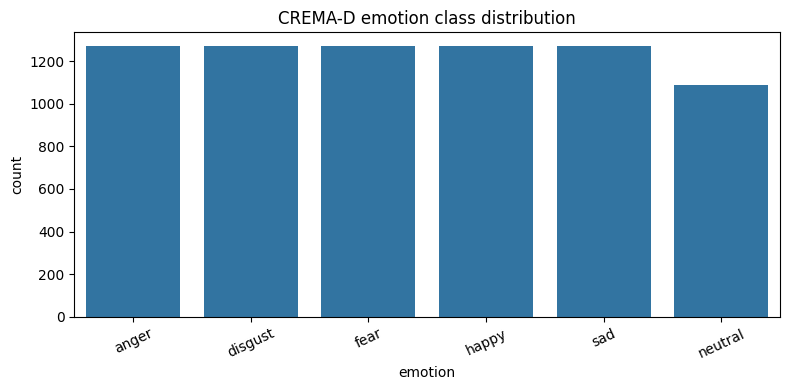

Sample: 1001_DFA_ANG_XX.wav | label: anger | sample rate: 16000 | duration: 2.28 sec


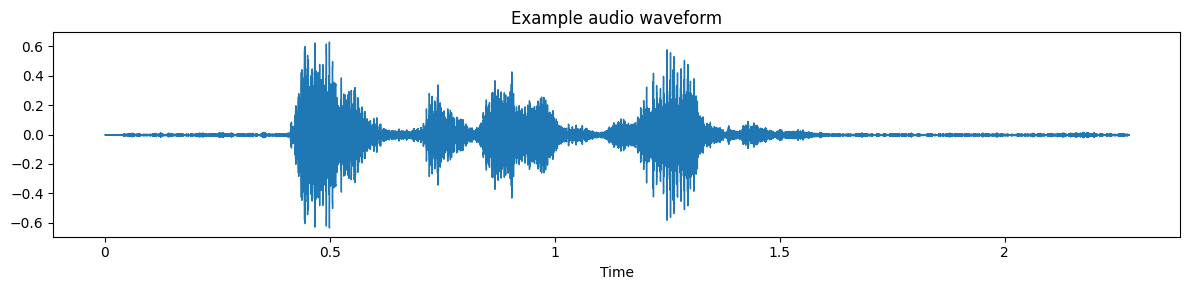

In [ ]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="emotion", order=df["emotion"].value_counts().index)
plt.title("CREMA-D emotion class distribution")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

sample_row = df.iloc[0]
y, sr = librosa.load(sample_row["path"], sr=None, mono=True)
print("Sample:", sample_row["filename"], "| label:", sample_row["emotion"], "| sample rate:", sr, "| duration:", round(len(y)/sr, 2), "sec")
plt.figure(figsize=(12, 3))
librosa.display.waveshow(y, sr=sr)
plt.title("Example audio waveform")
plt.tight_layout()
plt.show()

In [ ]:
# First reserve test actors, then split remaining actors into train and validation.
split1 = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
trainval_idx, test_idx = next(split1.split(df, groups=df["actor_id"]))
trainval_df = df.iloc[trainval_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

split2 = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED + 1)
train_idx, val_idx = next(split2.split(trainval_df, groups=trainval_df["actor_id"]))
train_df = trainval_df.iloc[train_idx].reset_index(drop=True)
val_df = trainval_df.iloc[val_idx].reset_index(drop=True)

print("Rows:", len(train_df), len(val_df), len(test_df))
print("Unique actors:", train_df.actor_id.nunique(), val_df.actor_id.nunique(), test_df.actor_id.nunique())
print("Actor overlap train/val:", set(train_df.actor_id) & set(val_df.actor_id))
print("Actor overlap train/test:", set(train_df.actor_id) & set(test_df.actor_id))
print("Actor overlap val/test:", set(val_df.actor_id) & set(test_df.actor_id))
for name, part in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(name, part["emotion"].value_counts().to_dict())

Rows: 4672 1218 1552
Unique actors: 57 15 19
Actor overlap train/val: set()
Actor overlap train/test: set()
Actor overlap val/test: set()
train {'anger': 798, 'disgust': 798, 'fear': 798, 'happy': 798, 'sad': 798, 'neutral': 682}
validation {'anger': 208, 'disgust': 208, 'fear': 208, 'happy': 208, 'sad': 208, 'neutral': 178}
test {'anger': 265, 'disgust': 265, 'fear': 265, 'happy': 265, 'sad': 265, 'neutral': 227}


In [ ]:
SR = 16000
DURATION = 4.0
N_SAMPLES = int(SR * DURATION)
N_MELS = 64
N_FFT = 1024
HOP_LENGTH = 256
EMOTIONS = ["anger", "disgust", "fear", "happy", "neutral", "sad"]
LABEL_TO_ID = {label: i for i, label in enumerate(EMOTIONS)}
ID_TO_LABEL = {i: label for label, i in LABEL_TO_ID.items()}

def extract_logmel(file_path):
    audio, _ = librosa.load(file_path, sr=SR, mono=True)
    if len(audio) < N_SAMPLES:
        audio = np.pad(audio, (0, N_SAMPLES - len(audio)))
    else:
        audio = audio[:N_SAMPLES]
    mel = librosa.feature.melspectrogram(
        y=audio, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH,
        n_mels=N_MELS, fmin=20, fmax=SR // 2, power=2.0
    )
    logmel = librosa.power_to_db(mel, ref=np.max)
    # Per-example normalization stabilizes input scale.
    logmel = (logmel - logmel.mean()) / (logmel.std() + 1e-6)
    return logmel.astype(np.float32)

# Precompute features once; this is CPU work and may take a few minutes.
feature_cache = {}
bad_files = []
for row in tqdm(df.itertuples(index=False), total=len(df), desc="Extracting log-Mel features"):
    try:
        feature_cache[row.path] = extract_logmel(row.path)
    except Exception as e:
        bad_files.append((row.path, str(e)))
print("Features cached:", len(feature_cache), "| failed files:", len(bad_files))
if bad_files:
    print("First errors:", bad_files[:3])

# Keep only files with successfully extracted features.
df = df[df["path"].isin(feature_cache)].reset_index(drop=True)
train_df = train_df[train_df["path"].isin(feature_cache)].reset_index(drop=True)
val_df = val_df[val_df["path"].isin(feature_cache)].reset_index(drop=True)
test_df = test_df[test_df["path"].isin(feature_cache)].reset_index(drop=True)

Extracting log-Mel features:   0%|          | 0/7442 [00:00<?, ?it/s]

Features cached: 7442 | failed files: 0


In [ ]:
class CREMADataset(Dataset):
    def __init__(self, frame, cache):
        self.frame = frame.reset_index(drop=True)
        self.cache = cache
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        x = self.cache[row["path"]]
        x = torch.from_numpy(x).unsqueeze(0)  # [channel=1, mel, time]
        y = torch.tensor(LABEL_TO_ID[row["emotion"]], dtype=torch.long)
        return x, y

BATCH_SIZE = 32
NUM_WORKERS = 0  # portable across Windows, notebooks, and Colab
train_loader = DataLoader(CREMADataset(train_df, feature_cache), batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(CREMADataset(val_df, feature_cache), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(CREMADataset(test_df, feature_cache), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

xb, yb = next(iter(train_loader))
print("Batch tensor shape:", xb.shape, "| labels:", yb.shape)

Batch tensor shape: torch.Size([32, 1, 64, 251]) | labels: torch.Size([32])


In [ ]:
class EmotionCNN(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.35),
            nn.Linear(128, num_classes)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

model = EmotionCNN(num_classes=len(EMOTIONS)).to(DEVICE)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

EmotionCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.35, inplace=False)
    (4): Line

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array(EMOTIONS),
    y=train_df["emotion"].values
)
class_weights = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
EPOCHS = 20
scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))

def evaluate_loader(model, loader):
    model.eval()
    all_y, all_pred, all_probs = [], [], []
    total_loss, total = 0.0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.amp.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")):
                logits = model(x)
                loss = criterion(logits, y)
            probs = torch.softmax(logits, dim=1)
            total_loss += loss.item() * y.size(0)
            total += y.size(0)
            all_y.extend(y.cpu().numpy())
            all_pred.extend(logits.argmax(1).cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    return total_loss / max(total, 1), np.array(all_y), np.array(all_pred), np.array(all_probs)

history = {"train_loss": [], "val_loss": [], "val_accuracy": [], "val_macro_f1": []}
best_f1 = -1
best_path = "best_cremad_emotion_cnn.pt"
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss, seen = 0.0, 0
    for x, y in tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS}", leave=False):
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")):
            logits = model(x)
            loss = criterion(logits, y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item() * y.size(0)
        seen += y.size(0)

    train_loss = running_loss / max(seen, 1)
    val_loss, y_true, y_pred, _ = evaluate_loader(model, val_loader)
    val_acc = accuracy_score(y_true, y_pred)
    val_f1 = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)[2]
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)
    history["val_macro_f1"].append(val_f1)
    print(f"Epoch {epoch:02d} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val acc {val_acc:.4f} | val macro-F1 {val_f1:.4f}")

    if val_f1 > best_f1:
        best_f1 = val_f1
        torch.save({"model_state_dict": model.state_dict(), "emotions": EMOTIONS}, best_path)

print(f"Training time: {(time.time()-start_time)/60:.1f} minutes")
print("Best validation macro-F1:", round(best_f1, 4))

Epoch 1/20:   0%|          | 0/146 [00:00<?, ?it/s]

Epoch 01 | train loss 1.5420 | val loss 1.4873 | val acc 0.3875 | val macro-F1 0.3163


Epoch 2/20:   0%|          | 0/146 [00:00<?, ?it/s]

Epoch 02 | train loss 1.4215 | val loss 1.3764 | val acc 0.4507 | val macro-F1 0.4380


Epoch 3/20:   0%|          | 0/146 [00:00<?, ?it/s]

...

Epoch 18 | train loss 1.1098 | val loss 1.2158 | val acc 0.5312 | val macro-F1 0.5266


Epoch 19/20:   0%|          | 0/146 [00:00<?, ?it/s]

Epoch 19 | train loss 1.1080 | val loss 1.1756 | val acc 0.5608 | val macro-F1 0.5482


Epoch 20/20:   0%|          | 0/146 [00:00<?, ?it/s]

Epoch 20 | train loss 1.1000 | val loss 1.2075 | val acc 0.5517 | val macro-F1 0.5412
Training time: 0.6 minutes
Best validation macro-F1: 0.5482


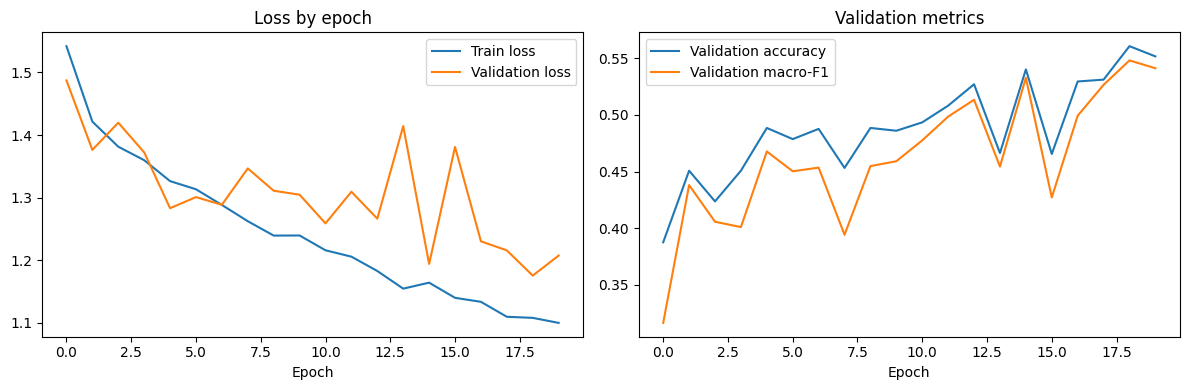

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["train_loss"], label="Train loss")
axes[0].plot(history["val_loss"], label="Validation loss")
axes[0].set_title("Loss by epoch"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(history["val_accuracy"], label="Validation accuracy")
axes[1].plot(history["val_macro_f1"], label="Validation macro-F1")
axes[1].set_title("Validation metrics"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.show()

Test loss: 1.2302
Test accuracy: 0.5271
Macro precision: 0.5304
Macro recall: 0.5303
Macro F1-score: 0.5129

Classification report:
              precision    recall  f1-score   support

       anger       0.63      0.81      0.71       265
     disgust       0.51      0.29      0.37       265
        fear       0.55      0.33      0.41       265
       happy       0.53      0.43      0.47       265
     neutral       0.53      0.66      0.59       227
         sad       0.44      0.66      0.53       265

    accuracy                           0.53      1552
   macro avg       0.53      0.53      0.51      1552
weighted avg       0.53      0.53      0.51      1552



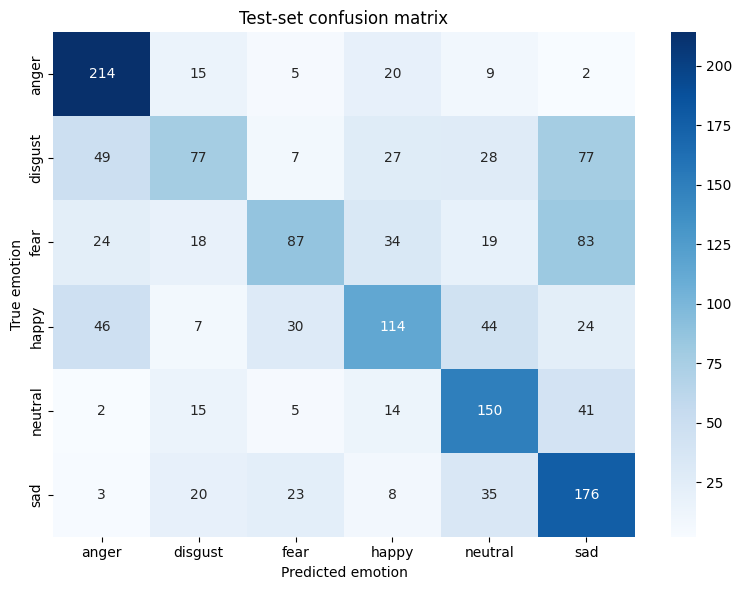

In [ ]:
checkpoint = torch.load(best_path, map_location=DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
test_loss, y_test, pred_test, prob_test = evaluate_loader(model, test_loader)

test_acc = accuracy_score(y_test, pred_test)
precision, recall, macro_f1, _ = precision_recall_fscore_support(
    y_test, pred_test, average="macro", zero_division=0
)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")
print(f"Macro precision: {precision:.4f}")
print(f"Macro recall: {recall:.4f}")
print(f"Macro F1-score: {macro_f1:.4f}")
print("\nClassification report:")
print(classification_report(y_test, pred_test, labels=np.arange(len(EMOTIONS)), target_names=EMOTIONS, zero_division=0))

cm = confusion_matrix(y_test, pred_test, labels=np.arange(len(EMOTIONS)))
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=EMOTIONS, yticklabels=EMOTIONS)
plt.xlabel("Predicted emotion")
plt.ylabel("True emotion")
plt.title("Test-set confusion matrix")
plt.tight_layout()
plt.show()

In [ ]:
def predict_emotion(audio_path):
    feature = extract_logmel(str(audio_path))
    x = torch.from_numpy(feature).unsqueeze(0).unsqueeze(0).to(DEVICE)
    model.eval()
    with torch.no_grad():
        logits = model(x)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()
    best = int(np.argmax(probs))
    return ID_TO_LABEL[best], float(probs[best]), {ID_TO_LABEL[i]: float(probs[i]) for i in range(len(EMOTIONS))}

AUDIO_TO_TEST = test_df.iloc[0]["path"]
predicted_emotion, confidence, all_scores = predict_emotion(AUDIO_TO_TEST)
print("File:", AUDIO_TO_TEST)
print("Predicted emotion:", predicted_emotion)
print(f"Confidence: {confidence:.2%}")
display(pd.DataFrame({"emotion": list(all_scores.keys()), "probability": list(all_scores.values())}).sort_values("probability", ascending=False))

File: /root/.cache/kagglehub/datasets/ejlok1/cremad/versions/1/AudioWAV/1001_DFA_ANG_XX.wav
Predicted emotion: anger
Confidence: 78.47%


,emotion,probability
0,anger,0.784714
3,happy,0.126873
1,disgust,0.062681
4,neutral,0.016134
2,fear,0.007974
5,sad,0.001625


In [ ]:
torch.save({
    "model_state_dict": model.state_dict(),
    "emotions": EMOTIONS,
    "sample_rate": SR,
    "duration": DURATION,
    "n_mels": N_MELS,
    "n_fft": N_FFT,
    "hop_length": HOP_LENGTH
}, "cremad_emotion_cnn_final.pt")

predictions_df = pd.DataFrame({
    "true_emotion": [ID_TO_LABEL[int(i)] for i in y_test],
    "predicted_emotion": [ID_TO_LABEL[int(i)] for i in pred_test],
    "confidence": prob_test.max(axis=1)
})
predictions_df.to_csv("cremad_test_predictions.csv", index=False)
print("Saved model: cremad_emotion_cnn_final.pt")
print("Saved predictions: cremad_test_predictions.csv")
display(predictions_df.head())

Saved model: cremad_emotion_cnn_final.pt
Saved predictions: cremad_test_predictions.csv


/usr/local/lib/python3.13/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,true_emotion,predicted_emotion,confidence
0,anger,anger,0.784668
1,disgust,happy,0.346924
2,fear,happy,0.449463
3,happy,happy,0.499756
4,neutral,neutral,0.618164
